# 03 · Modelagem e avaliação

Este notebook compara métodos de previsão, analisa onde o modelo escolhido erra, explica suas
previsões e mede a incerteza. Ele reproduz o que `python -m radar_dengue.model` faz em produção,
com mais detalhe.

**Desenho da avaliação**
- **Treino:** previsões cujo alvo cai antes de 2024 (2015 a 2023).
- **Teste:** previsões feitas a partir de janeiro de 2024, até 4 semanas antes do fim dos dados
  (as últimas semanas ainda recebem notificações atrasadas).
- **Horizontes:** 1, 2, 3 e 4 semanas à frente, um modelo para cada.
- **Métricas:** erro médio absoluto em casos (MAE), erro absoluto ponderado (WAPE: erro total ÷ casos
  totais) e erro quadrático médio em escala log (RMSE log, que dá peso parecido a todas as cidades).

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from radar_dengue import style
style.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import json
import lightgbm as lgb
import statsmodels.api as sm
from radar_dengue.features import FEATURES, add_targets, build_features, risk_level
from radar_dengue.model import PARAMS, fit_central, predict_central, split
from radar_dengue.compare import NB_FEATURES, alert_comparison, nb_features
from radar_dengue.geo import municipality_table, size_class, PORTES

raw = pd.read_parquet("data/raw/infodengue_sp.parquet")
d = nb_features(add_targets(build_features(raw), [1, 2, 3, 4]))
d = d.merge(municipality_table()[["geocode", "regiao"]], on="geocode", how="left")
d["porte"] = size_class(d.groupby("geocode")["pop"].transform("max"))
print(f"{len(FEATURES)} atributos:", ", ".join(FEATURES))

23 atributos: log_casos_lag0, log_casos_lag1, log_casos_lag2, log_casos_lag3, log_casos_lag52, log_media4, log_media8, crescimento_4s, inc100k_lag0, Rt, receptivo, tempmed_media4, tempmin_media4, tempmax_media4, umidmed_media4, umidmin_media4, umidmax_media4, tempmed_lag4, umidmed_lag4, sem_sin, sem_cos, log_pop, cresc_estado_4s


## 1. Métodos comparados

| Método | Ideia |
|---|---|
| **Ingênuo** | Os casos daqui a *h* semanas serão iguais aos desta semana. Difícil de bater no curto prazo. |
| **Sazonal ingênuo** | Os casos serão iguais aos da mesma semana do ano anterior. |
| **Regressão linear** | Mesmos 23 atributos, prevendo a variação de log(1 + casos), mas com relações lineares. Testa se precisamos de machine learning. |
| **Binomial negativa** | O modelo estatístico clássico para contagens sobredispersas, com a semana atual como *offset*. |
| **LightGBM em escala log** | *Gradient boosting* de árvores de decisão, prevendo a variação de log(1 + casos). |
| **LightGBM Poisson** | O mesmo algoritmo, mas com função de perda de Poisson, própria para contagens, e a semana atual como *offset*. |

Todos os métodos que aprendem preveem a **variação** em relação à semana atual (diretamente ou via
*offset*). Prever o nível fazia o LightGBM subestimar a epidemia de 2024, porque árvores não
extrapolam além dos valores vistos no treino.

A binomial negativa exigiu um cuidado extra: com atributos em nível, como log(casos) das semanas
anteriores, ela "explodia" nas cidades grandes durante a epidemia, prevendo mais de 500 mil casos
por semana para a capital. Com atributos em **variação** (diferenças entre semanas), que não dependem
do tamanho da cidade, ela passou a funcionar.

In [2]:
def metricas(real, prev):
    real, prev = np.asarray(real, float), np.clip(np.asarray(prev, float), 0, None)
    return {"MAE": np.mean(np.abs(real - prev)),
            "WAPE (%)": np.abs(real - prev).sum() / real.sum() * 100,
            "RMSE log": np.sqrt(np.mean((np.log1p(real) - np.log1p(prev)) ** 2))}

resultados, previsoes = [], {}
for h in [1, 2, 3, 4]:
    tr, te = split(d, h)
    y = f"y_h{h}"
    real = np.expm1(te[y]).to_numpy()
    atual = te["log_casos_lag0"].to_numpy()

    lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()
    p_lin = np.expm1(lin.predict(sm.add_constant(te[FEATURES])).to_numpy() + atual)
    nb = sm.GLM(np.expm1(tr[y]).round(), sm.add_constant(tr[NB_FEATURES]),
                family=sm.families.NegativeBinomial(alpha=0.3), offset=tr["log_casos_lag0"].to_numpy()).fit()
    p_nb = nb.predict(sm.add_constant(te[NB_FEATURES]), offset=atual)
    gbm_log = lgb.LGBMRegressor(**PARAMS).fit(tr[FEATURES], tr[y] - tr["log_casos_lag0"])
    p_log = np.expm1(gbm_log.predict(te[FEATURES]) + atual)
    gbm = fit_central(tr, h)
    p_gbm = predict_central(gbm, te)

    for nome, p in [("Ingênuo", np.expm1(atual)), ("Sazonal ingênuo", np.expm1(te["log_casos_lag52"])),
                    ("Regressão linear", p_lin), ("Binomial negativa", p_nb),
                    ("LightGBM log", p_log), ("LightGBM Poisson", p_gbm)]:
        resultados.append({"horizonte": h, "método": nome, **metricas(real, p)})
    previsoes[h] = te.assign(real=real, prev=p_gbm.clip(0), naive=np.expm1(atual))
    if h == 4:
        modelo_h4, treino_h4 = gbm, tr

res = pd.DataFrame(resultados)
ORDEM = ["Sazonal ingênuo", "Regressão linear", "Ingênuo", "Binomial negativa", "LightGBM log", "LightGBM Poisson"]
res.pivot(index="método", columns="horizonte", values="MAE").loc[ORDEM].round(1)

/tmp/ipykernel_996/3053201675.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_996/3053201675.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_996/3053201675.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


/tmp/ipykernel_996/3053201675.py:14: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lin = sm.OLS(tr[y] - tr["log_casos_lag0"], sm.add_constant(tr[FEATURES])).fit()


horizonte,1,2,3,4
método,,,,
Sazonal ingênuo,89.90,91.30,92.80,94.50
Regressão linear,20.40,29.50,36.60,42.40
Ingênuo,13.40,21.40,29.20,36.60
Binomial negativa,16.20,19.80,23.60,27.50
LightGBM log,12.20,18.10,22.20,26.40
LightGBM Poisson,11.60,17.00,21.00,25.80


In [3]:
res.pivot(index="método", columns="horizonte", values="WAPE (%)").loc[ORDEM].round(1)

horizonte,1,2,3,4
método,,,,
Sazonal ingênuo,129.10,130.80,132.90,135.50
Regressão linear,29.40,42.30,52.40,60.80
Ingênuo,19.20,30.70,41.70,52.50
Binomial negativa,23.20,28.40,33.80,39.50
LightGBM log,17.50,25.90,31.80,37.80
LightGBM Poisson,16.70,24.40,30.00,37.00


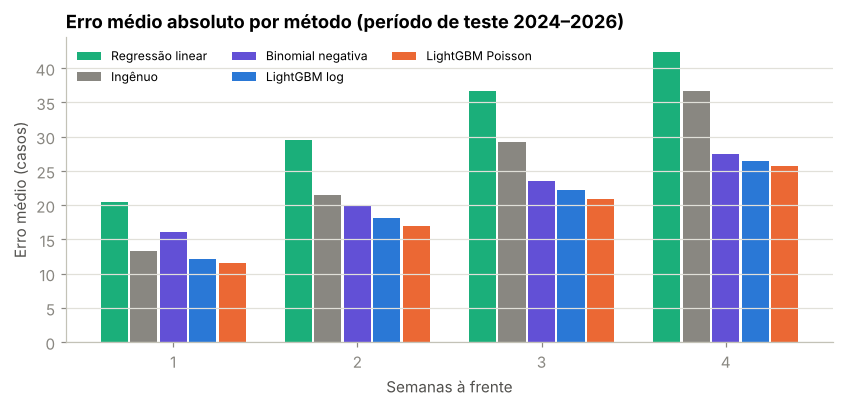

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
cores = {"Regressão linear": style.TERCEIRA, "Ingênuo": style.BASELINE, "Binomial negativa": "#6250d6",
         "LightGBM log": style.OBSERVADO, "LightGBM Poisson": style.PREVISTO}
larg = 0.16
for i, (nome, cor) in enumerate(cores.items()):
    v = res[res["método"] == nome].set_index("horizonte")["MAE"]
    ax.bar(v.index + (i - 2) * larg, v.values, width=larg * 0.92, color=cor, label=nome)
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Semanas à frente"); ax.set_ylabel("Erro médio (casos)")
ax.set_title("Erro médio absoluto por método (período de teste 2024–2026)")
ax.legend(ncols=3, loc="upper left", fontsize=8); plt.show()

**Leitura:**

- O **sazonal ingênuo** é o pior de longe: repetir o ano anterior não funciona quando os anos são tão
  diferentes entre si (2023 foi 5 vezes menor que 2024).
- A **regressão linear**, mesmo com todos os atributos, perde do ingênuo em todos os horizontes. As
  relações são não lineares: o efeito de "crescimento rápido" depende da época do ano e do tamanho
  da epidemia.
- A **binomial negativa**, referência estatística clássica para contagens, perde do ingênuo com 1
  semana de antecedência, mas fica perto do LightGBM com 3 e 4 semanas (27,5 contra 25,8 casos).
  Um modelo estatístico bem especificado já captura boa parte do sinal.
- O **LightGBM Poisson** é o melhor em todos os horizontes: cerca de 13% menos erro que o ingênuo
  em 1 semana e 30% em 4 semanas. A função de perda de Poisson melhorou o LightGBM em escala log
  em 2% a 6%, e ele virou o modelo de produção.
- O WAPE do modelo escolhido vai de cerca de 17% (1 semana) a 37% (4 semanas) dos casos totais.
  Prever dengue com 1 mês de antecedência continua difícil; o modelo reduz o erro, mas não o elimina.

O notebook 02 testa se essas diferenças são estatisticamente significativas.

### 1.1 E o SARIMAX?

O modelo clássico para uma série temporal é o SARIMAX. Ele foi ajustado **cidade por cidade**, nas
cidades com mais de 100 mil habitantes, onde ele tem condições justas (nas pequenas, com muitos zeros,
um modelo para dados contínuos não é apropriado):

- em log(1 + casos), com a ordem ARIMA escolhida por AIC;
- sazonalidade anual por termos de Fourier (regressão harmônica dinâmica), já que um SARIMA com
  período de 52 semanas é instável;
- numa segunda versão, com temperatura e umidade defasadas, já conhecidas no momento da previsão;
- parâmetros estimados até 2023 e mantidos fixos no teste, com o filtro de Kalman incorporando cada
  semana nova, a mesma regra dos outros métodos.

A comparação usa **exatamente as mesmas cidades, semanas e horizontes** para todos os métodos. As
previsões do SARIMAX são geradas por `python -m radar_dengue.sarimax` (cerca de 15 minutos). A teoria
está em [`docs/teoria/09_sarimax.md`](../docs/teoria/09_sarimax.md).

In [5]:
from radar_dengue.compare import sarimax_comparison
sar = sarimax_comparison(d)
tab_sar = sar.pivot(index="método", columns="horizonte", values="MAE")
ordem_sar = ["Repetir a semana atual (baseline)", "SARIMAX (sazonalidade de Fourier)", "SARIMAX com clima",
             "Binomial negativa", "LightGBM Poisson (modelo escolhido)"]
print(f"{sar['cidades'].iloc[0]} cidades, {sar['linhas'].iloc[0]:,} previsões por horizonte")
tab_sar.loc[[m for m in ordem_sar if m in tab_sar.index]].round(1)

82 cidades, 11,644 previsões por horizonte


horizonte,1,2,3,4
método,,,,
Repetir a semana atual (baseline),67.70,115.30,161.20,205.00
SARIMAX (sazonalidade de Fourier),87.80,134.20,170.90,200.10
SARIMAX com clima,88.40,134.60,171.30,200.60
Binomial negativa,81.00,99.50,120.20,142.80
LightGBM Poisson (modelo escolhido),57.20,89.10,111.70,141.30


**Leitura.** Nas 82 cidades com mais de 100 mil habitantes, o SARIMAX erra **mais que o próprio baseline** com 1 a 3 semanas (87,8 contra 67,7 casos com 1 semana) e só empata com 4 semanas (200,1 contra 205,0). A versão com clima não melhora nada. A binomial negativa e o LightGBM, modelos globais, ficam bem à frente (cerca de 141 a 143 com 4 semanas).

Por que o modelo clássico perde aqui:

- **Reversão à média sazonal.** Em 64 das 82 cidades, o AIC escolheu um modelo sem diferenciação ($d = 0$), que puxa a previsão de volta para o nível sazonal típico. Em 2024, com uma epidemia muito acima do normal, esses modelos **subestimaram** em média 460 casos por semana com 4 semanas de antecedência. Nas 18 cidades com $d = 1$, o viés foi de só 30 casos, e o SARIMAX bateu o baseline.
- **Cada cidade sozinha.** O SARIMAX não usa a tendência do estado nem o que acontece nas cidades vizinhas, a informação que mais ajuda a antecipar uma epidemia.
- **Linear no log e com erros normais**, enquanto as epidemias têm crescimento explosivo e saltos.

**Conclusão:** o SARIMAX é o padrão para uma série isolada e bem comportada. Para centenas de séries relacionadas, com epidemias fora do padrão histórico, os dados confirmam a escolha de um modelo global. A teoria está em [docs/teoria/09_sarimax.md](../docs/teoria/09_sarimax.md).

## 2. Ajuste de hiperparâmetros

Testamos 6 configurações do LightGBM com **validação cruzada temporal** dentro do período de treino:
treina até o ano anterior e valida em 2021, depois em 2022, depois em 2023. O período de teste nunca é
usado nessa escolha. O resultado fica salvo em `models/tuning.json`; para refazer a busca (cerca de 5
minutos), mude `REFAZER` para `True`.

In [6]:
REFAZER = False
if REFAZER:
    grade = [dict(num_leaves=nl, min_child_samples=mc, learning_rate=lr, n_estimators=ne)
             for nl, mc, lr, ne in [(63, 50, 0.03, 600), (31, 100, 0.05, 400), (127, 50, 0.03, 600),
                                    (15, 200, 0.05, 500), (63, 200, 0.02, 1000), (255, 100, 0.03, 400)]]
    h, y = 4, "y_h4"
    b = d.dropna(subset=[y, "log_casos_lag52"])
    saida = []
    for g in grade:
        erros = []
        for ano in [2021, 2022, 2023]:
            tr = b[b["data_alvo_h4"] < f"{ano}-01-01"]
            va = b[(b["data_iniSE"] >= f"{ano}-01-01") & (b["data_alvo_h4"] < f"{ano + 1}-01-01")]
            m = lgb.LGBMRegressor(**{**PARAMS, **g}).fit(tr[FEATURES], tr[y] - tr["log_casos_lag0"])
            p = np.expm1(m.predict(va[FEATURES]) + va["log_casos_lag0"].to_numpy()).clip(0)
            erros.append(np.mean(np.abs(np.expm1(va[y]) - p)))
        saida.append([g, float(np.mean(erros))])
    json.dump(saida, open("models/tuning.json", "w"))

tuning = pd.DataFrame([{**g, "MAE validação (média 2021–2023)": e}
                       for g, e in json.load(open("models/tuning.json"))]).sort_values("MAE validação (média 2021–2023)")
tuning

,num_leaves,min_child_samples,learning_rate,n_estimators,MAE validação (média 2021–2023)
2,127,50,0.03,600,8.09
5,255,100,0.03,400,8.10
0,63,50,0.03,600,8.18
4,63,200,0.02,1000,8.19
1,31,100,0.05,400,8.23
3,15,200,0.05,500,8.24


As configurações ficam a cerca de 2% umas das outras (entre 8,1 e 8,2 casos de erro médio). A
configuração em uso (63 folhas, 600 árvores) está no meio do grupo, e a melhor seria só 1% superior,
diferença menor que a variação entre anos de validação. **O desempenho vem dos atributos e do
desenho do alvo, não do ajuste fino**, por isso mantivemos a configuração original, mais simples e
mais rápida. A busca foi feita com a versão em escala log do LightGBM; como a versão Poisson usa os
mesmos atributos e um alvo equivalente, não esperamos que a conclusão mude.

## 3. Onde o modelo erra

### 3.1 Por porte do município (horizonte de 4 semanas)

In [7]:
p4 = previsoes[4]
def resumo(grupo):
    t = p4.groupby(grupo, observed=True).apply(lambda x: pd.Series({
        "municípios": x["geocode"].nunique(),
        "casos reais médios": x["real"].mean(),
        "MAE modelo": np.mean(np.abs(x["real"] - x["prev"])),
        "MAE ingênuo": np.mean(np.abs(x["real"] - x["naive"])),
        "WAPE modelo (%)": np.abs(x["real"] - x["prev"]).sum() / x["real"].sum() * 100}))
    t["redução do erro (%)"] = (1 - t["MAE modelo"] / t["MAE ingênuo"]) * 100
    return t
resumo("porte").round(1)

,municípios,casos reais médios,MAE modelo,MAE ingênuo,WAPE modelo (%),redução do erro (%)
porte,,,,,,
<20 mil,379.00,7.20,4.20,5.40,58.80,21.70
20–100 mil,184.00,44.30,18.70,26.00,42.20,28.00
100–500 mil,73.00,206.90,71.50,109.40,34.50,34.60
>500 mil,9.00,"2,112.70",707.70,980.80,33.50,27.80


- O modelo **melhora o erro em todos os portes**, de cerca de 22% nas cidades pequenas a cerca de
  28% a 35% nas médias e grandes.
- O **erro relativo (WAPE) é maior nas cidades pequenas**: com poucos casos, qualquer diferença pesa
  muito em proporção. Nelas, a previsão vale mais como sinal de tendência do que como número exato.

### 3.2 Por região

In [8]:
resumo('regiao').round(1)

,municípios,casos reais médios,MAE modelo,MAE ingênuo,WAPE modelo (%),redução do erro (%)
regiao,,,,,,
Oeste,166.00,19.10,7.80,10.60,40.90,26.60
Centro,227.00,31.40,12.20,17.10,38.90,28.60
Leste,252.00,137.70,49.80,71.30,36.20,30.20


O ganho aparece nas três regiões (de 27% a 30% menos erro) e é um pouco maior no **Leste**, a região
que teve a epidemia atípica de 2024. O erro relativo (WAPE) também é menor no Leste, porque lá estão
as cidades grandes, cujas séries são mais suaves.

### 3.3 Por fase da epidemia

In [9]:
mudanca = np.log1p(p4["real"]) - np.log1p(p4["naive"])
p4["fase"] = np.select([mudanca > 0.4, mudanca < -0.4], ["Subida forte", "Queda forte"], "Estável")
fases = p4.groupby("fase").apply(lambda x: pd.Series({
    "% das observações": len(x) / len(p4) * 100,
    "MAE modelo": np.mean(np.abs(x["real"] - x["prev"])),
    "MAE ingênuo": np.mean(np.abs(x["real"] - x["naive"])),
    "viés modelo (prev − real)": np.mean(x["prev"] - x["real"])}))
fases["redução do erro (%)"] = (1 - fases["MAE modelo"] / fases["MAE ingênuo"]) * 100
fases.round(1)

,% das observações,MAE modelo,MAE ingênuo,viés modelo (prev − real),redução do erro (%)
fase,,,,,
Estável,43.90,22.60,12.70,-15.20,-77.40
Queda forte,30.00,13.30,54.60,6.40,75.70
Subida forte,26.10,45.50,56.30,-44.30,19.10


A fase é definida pela variação real em 4 semanas: "subida forte" quando os casos crescem mais de
cerca de 50% (variação acima de 0,4 em log), "queda forte" quando caem na mesma proporção.

- **Na fase estável, o ingênuo ganha.** É esperado: se os casos não mudam, "repetir a semana atual"
  é quase a resposta certa por definição. O modelo, que tenta antecipar mudanças, erra um pouco mais.
- **Nas quedas fortes, o modelo reduz o erro em cerca de 75%**: ele aprendeu que epidemias acabam
  depois do pico e no fim do verão, algo que o ingênuo não sabe.
- **Nas subidas fortes, o modelo ganha menos (cerca de 19%) e subestima** (viés negativo): antecipa
  parte do crescimento, mas não todo. É o erro mais caro para a vigilância.

Essa assimetria é o principal ponto a melhorar, por exemplo com casos nos municípios vizinhos, que
mostram a epidemia chegando antes.

### 3.4 O teste é otimista? Sensibilidade ao atraso de notificação

Há uma limitação importante na avaliação. No teste, os atributos de cada semana usam os casos
**já consolidados**, os números finais, conhecidos meses depois. Na vida real, no momento da previsão
a semana atual tem só cerca de 28% dos casos notificados, e o modelo usa a estimativa corrigida
(nowcast) do InfoDengue, que tem erro. O Rt e o nível de alerta históricos também são as versões
finais. Isso torna o teste **otimista**: o erro real em produção tende a ser maior.

O InfoDengue não guarda as estimativas antigas de cada semana, então não dá para refazer o teste
exatamente como seria em tempo real. Mas dá para medir a **sensibilidade**: somamos um erro aleatório
aos casos da semana atual (e um erro menor à semana anterior), simulando um nowcast impreciso, e
aplicamos o mesmo erro ao baseline, que também dependeria do nowcast.

In [10]:
rng = np.random.default_rng(0)
sens = []
for h in [1, 4]:
    tr, te = split(d, h)
    m = fit_central(tr, h)
    real = np.expm1(te[f"y_h{h}"]).to_numpy()
    for sd in [0.0, 0.1, 0.25]:
        t = te.copy()
        e0, e1 = rng.normal(0, sd, len(t)), rng.normal(0, sd / 2, len(t))
        t["log_casos_lag0"] += e0
        t["log_casos_lag1"] += e1
        t["log_media4"] += (e0 + e1) / 4
        t["log_media8"] += (e0 + e1) / 8
        t["crescimento_4s"] += e0
        t["inc100k_lag0"] = np.expm1(t["log_casos_lag0"].clip(0)) / t["pop"] * 1e5
        erro_m = np.mean(np.abs(real - predict_central(m, t)))
        erro_b = np.mean(np.abs(real - np.expm1(t["log_casos_lag0"].clip(0))))
        sens.append({"horizonte": h, "erro do nowcast (desvio em log)": sd,
                     "erro modelo": erro_m, "erro baseline": erro_b,
                     "redução (%)": (1 - erro_m / erro_b) * 100})
pd.DataFrame(sens).set_index(["horizonte", "erro do nowcast (desvio em log)"]).round(1)

erro modelo  erro baseline  \
horizonte erro do nowcast (desvio em log)                               
1         0.00                                   11.60          13.40   
          0.10                                   13.40          14.90   
          0.25                                   17.30          19.40   
4         0.00                                   25.80          36.60   
          0.10                                   26.40          37.40   
          0.25                                   27.40          39.60   

                                           redução (%)  
horizonte erro do nowcast (desvio em log)               
1         0.00                                   13.00  
          0.10                                   10.30  
          0.25                                   10.90  
4         0.00                                   29.60  
          0.10                                   29.50  
          0.25                                   30.90

Um desvio de 0,1 em log corresponde a cerca de 10% de erro no nowcast; 0,25, a cerca de 25%.

- **Com 1 semana de antecedência, o erro absoluto é muito sensível** ao nowcast: com 25% de erro, ele
  sobe de cerca de 12 para 17 casos. Mas o baseline piora na mesma medida (de 13 para 19), e o modelo
  continua cerca de 10% melhor.
- **Com 4 semanas, o efeito é pequeno** (de cerca de 26 para 27 casos), e a vantagem sobre o baseline
  se mantém em cerca de 30%.

**Conclusão:** o erro absoluto reportado no teste é um limite inferior, especialmente no curto prazo,
mas a vantagem do modelo sobre o baseline é robusta. O desempenho real só vai ser conhecido com o
monitoramento em produção, que compara previsões feitas em tempo real com os casos consolidados.

### 3.5 Exemplo: a capital durante a epidemia de 2024

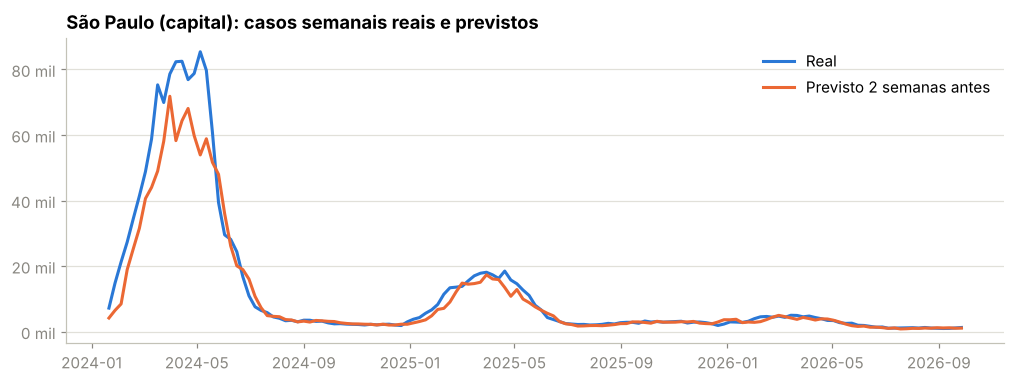

In [11]:
sp = previsoes[2].query("municipio == 'São Paulo'").sort_values("data_alvo_h2")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(sp["data_alvo_h2"], sp["real"], color=style.OBSERVADO, label="Real")
ax.plot(sp["data_alvo_h2"], sp["prev"], color=style.PREVISTO, label="Previsto 2 semanas antes")
ax.set_title("São Paulo (capital): casos semanais reais e previstos")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil"); ax.legend(); plt.show()

## 4. Explicabilidade

### 4.1 O que o modelo usa, em média

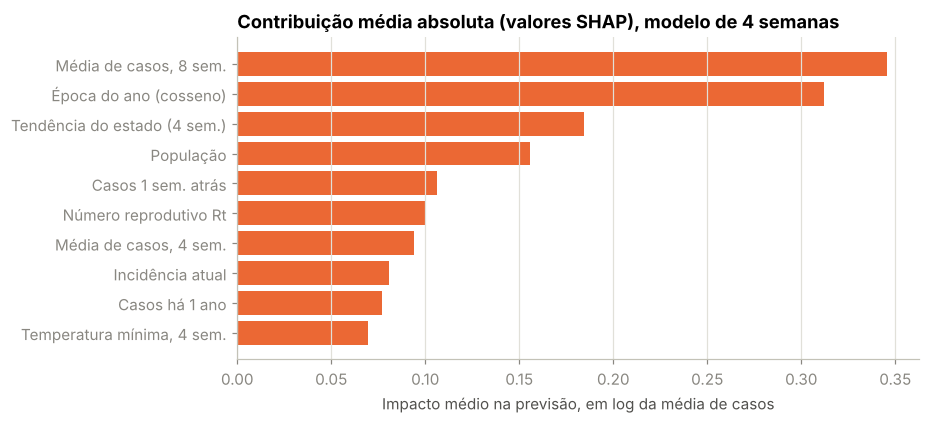

In [12]:
amostra = previsoes[4].sample(20000, random_state=0)
contrib = modelo_h4.predict(amostra[FEATURES], pred_contrib=True)[:, :-1]
shap_medio = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()

nomes = {"inc100k_lag0": "Incidência atual", "cresc_estado_4s": "Tendência do estado (4 sem.)",
         "sem_cos": "Época do ano (cosseno)", "sem_sin": "Época do ano (seno)", "Rt": "Número reprodutivo Rt",
         "log_media8": "Média de casos, 8 sem.", "log_media4": "Média de casos, 4 sem.",
         "log_casos_lag0": "Casos da semana atual", "crescimento_4s": "Crescimento em 4 sem.",
         "tempmin_media4": "Temperatura mínima, 4 sem.", "log_casos_lag52": "Casos há 1 ano",
         "log_pop": "População", "log_casos_lag1": "Casos 1 sem. atrás",
         "log_casos_lag2": "Casos 2 sem. atrás", "log_casos_lag3": "Casos 3 sem. atrás"}
top = shap_medio.tail(10)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([nomes.get(f, f) for f in top.index], top.values, color=style.PREVISTO)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Contribuição média absoluta (valores SHAP), modelo de 4 semanas")
ax.set_xlabel("Impacto médio na previsão, em log da média de casos"); plt.show()

Os valores **SHAP** decompõem cada previsão na contribuição de cada atributo (o LightGBM calcula
isso exatamente com `pred_contrib=True`). Em média, o que mais move a previsão é o **nível recente de
casos** (média de 8 semanas), a **época do ano**, a **tendência do estado** e o **porte do município**,
seguidos dos casos recentes e do Rt. O clima aparece por último entre os dez mais importantes,
coerente com o notebook 02: depois de saber a época do ano e a situação atual, a temperatura
acrescenta pouca informação.

### 4.2 Uma previsão explicada

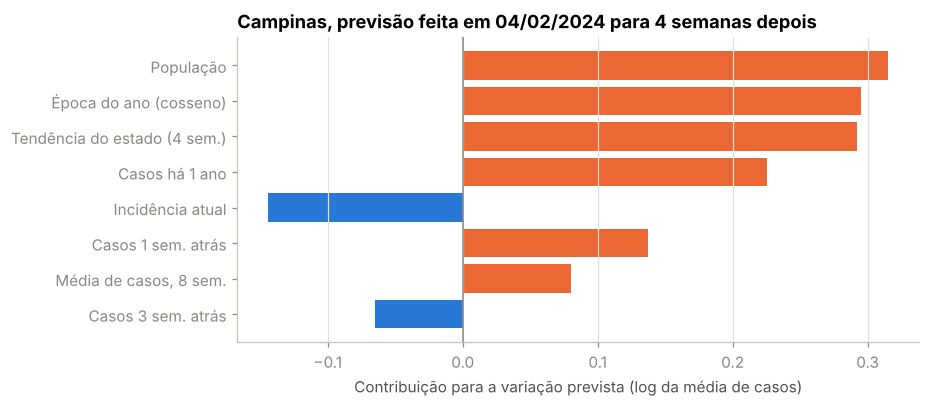

Casos na semana da previsão: 2,432 | previstos: 3,557 | reais: 6,550


In [13]:
ex = previsoes[4].query("municipio == 'Campinas'").sort_values("data_iniSE")
ex = ex[ex["data_iniSE"] == pd.Timestamp("2024-02-04")]
c = pd.Series(modelo_h4.predict(ex[FEATURES], pred_contrib=True)[0][:-1], index=FEATURES)
c = c.reindex(c.abs().sort_values().index).tail(8)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([nomes.get(f, f) for f in c.index], c.values,
        color=[style.PREVISTO if v > 0 else style.OBSERVADO for v in c.values])
ax.axvline(0, color="#898781", linewidth=1); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Campinas, previsão feita em 04/02/2024 para 4 semanas depois")
ax.set_xlabel("Contribuição para a variação prevista (log da média de casos)"); plt.show()
print(f"Casos na semana da previsão: {np.expm1(ex['log_casos_lag0'].iloc[0]):,.0f} | "
      f"previstos: {ex['prev'].iloc[0]:,.0f} | reais: {ex['real'].iloc[0]:,.0f}")

Em fevereiro de 2024, no começo da epidemia recorde, Campinas tinha cerca de 2.400 casos por semana.
O modelo previu cerca de 3.600 para 4 semanas depois; o real foi cerca de 6.500.

As barras mostram por quê. O **porte da cidade**, a **época do ano** e a **tendência de alta no
estado** empurraram a previsão para cima (laranja), mas a **incidência atual já alta** puxou para
baixo (azul): no histórico de treino, níveis altos costumavam ser seguidos de estabilização. Em 2024
isso não aconteceu. É um exemplo concreto do viés nas subidas fortes visto na seção 3.3, e é esse
tipo de explicação que permite a um gestor de saúde entender, e questionar, um alerta.

## 5. Incerteza: intervalos de previsão calibrados

Uma previsão de "45 casos" esconde quanto ela pode errar. Para cada horizonte, treinamos modelos de
**regressão quantílica** (objetivo `quantile` do LightGBM) que estimam os limites de três intervalos:
**50%** (a faixa mais provável), **80%** e **95%** (o pior cenário plausível).

Regressões quantílicas sozinhas costumam ficar estreitas demais em períodos atípicos. Por isso
usamos **calibração conformal** (*Conformalized Quantile Regression*, Romano, Patterson e Candès,
2019):

1. Os modelos quantílicos são ajustados com dados **até 2022**.
2. Em **2023**, um período separado, medimos o quanto os intervalos erraram e calculamos quanto
   alargá-los para atingir a cobertura nominal.
3. A cobertura é avaliada em **2024–2026**, período que não entrou em nenhuma das duas etapas.

São **intervalos de previsão** (sobre um valor futuro), e não intervalos de confiança (sobre um
parâmetro): por isso são mais largos e é comum mostrar níveis como 50% e 80%, além de 95%.

In [14]:
from radar_dengue.intervals import NIVEIS, conformal_adjustment, coverage, fit_quantiles, predict_bounds
from radar_dengue.model import consolidated
from radar_dengue.config import TEST_START

base4 = consolidated(d, 4)
alvo4 = base4["data_alvo_h4"]
quantis = fit_quantiles(base4[alvo4 < "2023-01-01"], 4)
calib = base4[(alvo4 >= "2023-01-01") & (alvo4 < TEST_START)]
teste4 = base4[base4["data_iniSE"] >= TEST_START]

cob = []
for nivel in NIVEIS:
    q = conformal_adjustment(quantis, calib, 4, nivel)
    lo, hi = predict_bounds(quantis, teste4, nivel, q)
    dentro = (teste4["y_h4"].to_numpy() >= lo) & (teste4["y_h4"].to_numpy() <= hi)
    linha = {"nível": f"{nivel}%", "sem calibração (%)": coverage(quantis, teste4, 4, nivel, 0) * 100,
             "calibrado (%)": dentro.mean() * 100}
    por_porte = pd.Series(dentro).groupby(teste4["porte"].values, observed=True).mean() * 100
    linha.update({f"calibrado, {p} (%)": v for p, v in por_porte.items()})
    cob.append(linha)
pd.DataFrame(cob).set_index("nível").round(1)

,sem calibração (%),calibrado (%),"calibrado, <20 mil (%)","calibrado, 20–100 mil (%)","calibrado, 100–500 mil (%)","calibrado, >500 mil (%)"
nível,,,,,,
50%,51.60,52.80,58.10,47.50,41.10,35.50
80%,75.20,78.00,81.10,74.80,71.40,65.90
95%,90.30,94.60,95.50,93.80,92.20,91.00


A calibração conformal supõe que os erros do período de calibração (2023) se parecem com os do
período de uso. Isso não vale exatamente aqui, porque 2024 foi muito mais extremo que 2023; mesmo
assim, a cobertura ficou perto do nominal. Com 4 semanas de antecedência, a calibração aproxima a
cobertura do valor nominal: o intervalo de
95% passa de cerca de 90% para **cerca de 95%**, e o de 80% fica perto de 78%. A cobertura ainda
varia com o porte: é melhor nas cidades pequenas e pior nas grandes, cujas epidemias de 2024 foram
mais extremas que tudo no treino. Uma melhoria possível é calibrar por porte, separadamente.

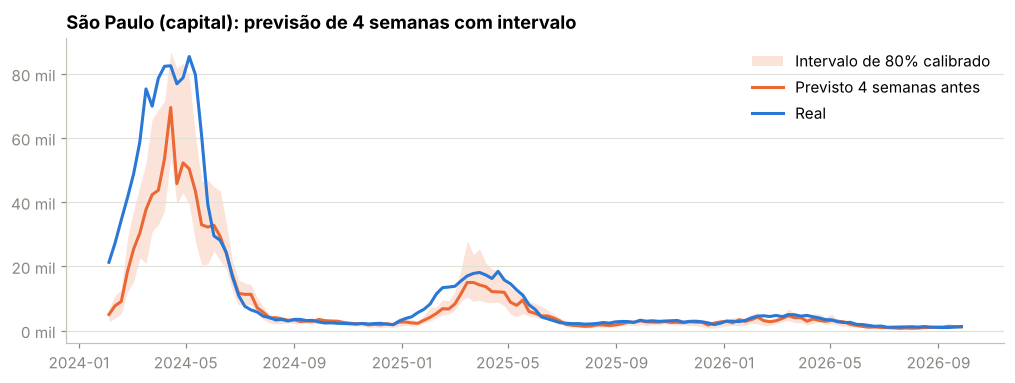

In [15]:
spq = teste4[teste4["municipio"] == "São Paulo"].sort_values("data_alvo_h4")
q80 = conformal_adjustment(quantis, calib, 4, 80)
lo, hi = predict_bounds(quantis, spq, 80, q80)
prev_sp = previsoes[4].query("municipio == 'São Paulo'").sort_values("data_alvo_h4")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(spq["data_alvo_h4"], np.expm1(lo), np.expm1(hi), color=style.PREVISTO, alpha=0.18, linewidth=0, label="Intervalo de 80% calibrado")
ax.plot(prev_sp["data_alvo_h4"], prev_sp["prev"], color=style.PREVISTO, label="Previsto 4 semanas antes")
ax.plot(spq["data_alvo_h4"], np.expm1(spq["y_h4"]), color=style.OBSERVADO, label="Real")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f} mil")
ax.set_title("São Paulo (capital): previsão de 4 semanas com intervalo"); ax.legend(); plt.show()

## 6. Comparação com o alerta oficial do InfoDengue

A comparação mais exigente não é com métodos ingênuos, mas com o sistema que a vigilância já usa. O
InfoDengue (Fiocruz/FGV) classifica cada município, toda semana, em quatro níveis; o **nível 4**
indica incidência acima do limiar epidêmico **do próprio município**.

**Pergunta:** o município estará no nível 4 daqui a *h* semanas?

- **Alerta oficial de hoje:** prevê que quem está no nível 4 hoje continuará nele.
- **Oficial + modelo:** soma ao alerta oficial os municípios que ainda **não** estão no nível 4, mas
  cuja incidência prevista pelo modelo passa de um limiar. O limiar é escolhido no período de
  treino, nunca no de teste.

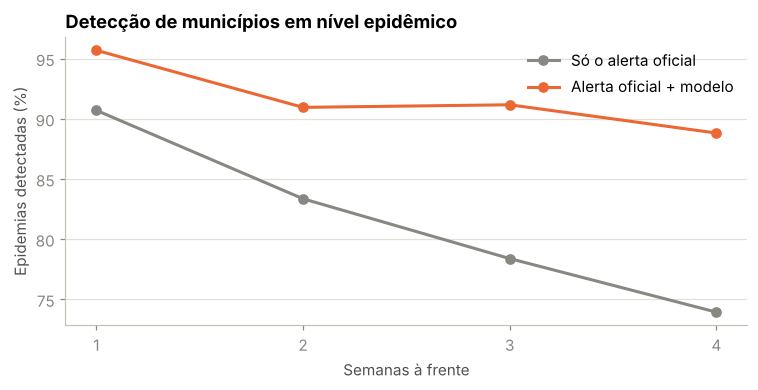

,oficial: precisão (%),oficial: detecção (%),oficial + modelo: precisão (%),oficial + modelo: detecção (%),novas epidemias detectadas (%),precisão dos alertas novos (%),limiar (casos por 100 mil)
semanas à frente,,,,,,,
1,90.40,90.70,75.90,95.70,53.60,19.40,150
2,82.70,83.40,70.80,90.90,45.60,27.40,150
3,77.30,78.40,60.40,91.20,59.10,25.80,100
4,72.30,73.90,57.40,88.80,57.10,28.40,100


In [16]:
alerta = alert_comparison(d.copy())
al = pd.DataFrame([{"semanas à frente": int(k[1:]),
                    "oficial: precisão (%)": v["oficial"]["precisao"] * 100,
                    "oficial: detecção (%)": v["oficial"]["recall"] * 100,
                    "oficial + modelo: precisão (%)": v["combinado"]["precisao"] * 100,
                    "oficial + modelo: detecção (%)": v["combinado"]["recall"] * 100,
                    "novas epidemias detectadas (%)": v["novas_detectadas_pelo_modelo"] * 100,
                    "precisão dos alertas novos (%)": v["precisao_alertas_novos"] * 100,
                    "limiar (casos por 100 mil)": v["limiar_incidencia"]} for k, v in alerta.items()])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(al["semanas à frente"], al["oficial: detecção (%)"], marker="o", color=style.BASELINE, label="Só o alerta oficial")
ax.plot(al["semanas à frente"], al["oficial + modelo: detecção (%)"], marker="o", color=style.PREVISTO, label="Alerta oficial + modelo")
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Semanas à frente"); ax.set_ylabel("Epidemias detectadas (%)")
ax.set_title("Detecção de municípios em nível epidêmico"); ax.legend(); plt.show()
al.set_index("semanas à frente").round(1)

**Leitura:**

- **O alerta oficial de hoje é muito bom para dizer quem continuará em epidemia**: com 1 semana de
  antecedência, acerta e detecta cerca de 90% dos casos. Faz sentido: epidemias duram semanas, e o
  InfoDengue usa um limiar próprio de cada município, que o modelo não conhece.
- **Mas, por definição, ele não antecipa municípios que ainda não entraram em epidemia.** O modelo
  detecta cerca de metade dessas novas epidemias (de 46% a 59%, conforme o horizonte).
- **Combinando os dois, a detecção com 4 semanas de antecedência sobe de cerca de 74% para 89%**
  dos municípios-semana que estarão em nível epidêmico. O
  custo é a precisão, que cai de cerca de 72% para 57%: só uma em cada quatro ou cinco novas
  entradas sinalizadas pelo modelo se confirma.

Uma ressalva: o nível de alerta histórico do InfoDengue também é a versão final, calculada com os
dados já consolidados, assim como os atributos do modelo (seção 3.4). A comparação é justa entre os
dois, mas ambos estão um pouco otimistas em relação ao uso em tempo real.

Ou seja, o modelo não substitui o sistema oficial, mas o **complementa** como um alerta precoce. Se
esse ganho vale os alarmes falsos depende do custo de cada um para a vigilância, uma decisão de
gestão, e o limiar pode ser ajustado para isso.

## Conclusões

1. **LightGBM Poisson é o melhor método em todos os horizontes**; regressão linear e repetição do
   ano anterior perdem até do baseline, e a binomial negativa fica perto só nos horizontes longos.
2. **O ganho cresce com o horizonte**: 13% menos erro em 1 semana e 30% em 4 semanas.
3. **Hiperparâmetros importam pouco** (cerca de 2% de diferença); o que importa é prever a variação, e
   não o nível, e usar uma função de perda própria para contagens.
4. **O teste é otimista em relação ao uso real**, porque usa casos já consolidados; com o erro do
   nowcast, o erro absoluto de curto prazo cresce, mas a vantagem sobre o baseline se mantém.
5. **Principal fraqueza:** subestimar subidas fortes. O maior ganho está em reconhecer o fim das epidemias.
6. **Intervalos calibrados:** com calibração conformal, os intervalos de 50%, 80% e 95% cobrem perto
   do nominal (o de 95% cobre cerca de 95% dos casos reais), mas ainda ficam estreitos nas cidades grandes.
7. **O modelo complementa o alerta oficial do InfoDengue**: junto com ele, a detecção de epidemias
   com 4 semanas de antecedência sobe de cerca de 74% para 89%, ao custo de mais alarmes falsos.

**Próximos passos de modelagem:** casos nos municípios vizinhos, calibração dos intervalos (*conformal
prediction* por porte) e ajuste do limiar de alerta priorizando o *recall*.